# Zero-Day Network Attack Detection with QORC

This notebook is a beginner-friendly walkthrough of using a **Quantum Optical Reservoir Computer (QORC)** to spot unusual network connections in the NSL-KDD dataset.

Each row in the data describes one network connection. We will teach models about normal connections and one known attack family (DoS), then test whether they can recognize attack families they never saw during training. That is a simplified experiment in **zero-day detection**.

## The journey
1. **Network dataset:** inspect the data and create a train/test split that keeps selected attack families unseen.
2. **Build the QORC:** turn each connection into four values, encode them as optical phases, and simulate a small photonic circuit.
3. **Training process:** compare a supervised classifier with detectors trained only on normal traffic.
4. **Compare and conclude:** review attack detection and false alarms, then discuss limitations.

> **Before you start:** keep `NSL_KDD_labeled.csv` in this folder and install packages from [`requirements.txt`](requirements.txt). In VS Code, select this folder's `.venv` as the notebook kernel. The correct Quandela package is named `perceval-quandela`, while Python imports it as `perceval`. If `from perceval.simulators import Simulator` raises `ModuleNotFoundError`, the kernel may have the unrelated PyPI package named `perceval`; remove that package from the selected environment with `python -m pip uninstall -y perceval`, then run `python -m pip install -r requirements.txt` and reselect the `.venv` kernel.

In [ ]:
import sys, importlib.util
try:
    import perceval as _p
    assert importlib.util.find_spec("perceval.simulators") and importlib.util.find_spec("sklearn")
    print("OK: Quandela perceval", _p.__version__, "|", sys.executable)
except Exception as e:
    raise RuntimeError(
        f"Wrong kernel environment: {sys.executable}\n"
        "Needs Quandela's 'perceval-quandela' + scikit-learn. The 'perceval' package (Bitergia/GrimoireLab) "
        "is a different project with the same module name.\n"
        "Fix: select the kernel '.venv' in oct_27_try, or run: "
        "pip uninstall -y perceval && pip install perceval-quandela scikit-learn") from e

In [2]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
import perceval as pcvl
from perceval.backends import SLOSBackend
from perceval.simulators import Simulator

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, recall_score, confusion_matrix, roc_auc_score

SEED = 42
rng = np.random.default_rng(SEED)
DATA = "NSL_KDD_labeled.csv"

## 1. Network dataset: what are we trying to detect?

NSL-KDD is a collection of network-connection records. A record contains measurements such as protocol, service, bytes sent, and connection counts. Its `label` says whether it is normal traffic or names a particular attack.

For this tutorial, individual attack labels are grouped into broad families. That makes it possible to hold out a whole family during training and test whether a model notices it later. The next cell checks that every label in this copy of the dataset is mapped.

In [3]:
df = pd.read_csv(DATA)

# Standard NSL-KDD attack -> family mapping (only names present in this file)
FAMILY = {
    'normal': 'normal',
    **dict.fromkeys(['neptune','smurf','back','teardrop','pod','land'], 'dos'),
    **dict.fromkeys(['satan','ipsweep','portsweep','nmap'], 'probe'),
    **dict.fromkeys(['guess_passwd','warezclient','warezmaster','imap','ftp_write','multihop','phf','spy'], 'r2l'),
    **dict.fromkeys(['buffer_overflow','rootkit','loadmodule','perl'], 'u2r'),
}
df['family'] = df['label'].map(FAMILY)
assert df['family'].notna().all(), df.loc[df['family'].isna(), 'label'].unique()
print(df['family'].value_counts())

family
normal    67343
dos       45927
probe     11656
r2l         995
u2r          52
Name: count, dtype: int64


### Create a zero-day-style train/test split

A **zero-day** here means an attack family that the model is not shown while learning. The split below trains on normal connections and DoS attacks. Probe, R2L, and U2R are withheld from training; **R2L is our main zero-day test family**. Their labels are used only to evaluate the finished models, never as training examples.

We use a manageable sample of normal, DoS, and probe records to keep optical simulation quick, and include all available R2L and U2R records because they are rare. The printed family counts and assertion below let us check the split. This is a controlled dataset experiment, not a claim that every real-world zero-day behaves the same way.

In [4]:
N_NORMAL_TRAIN, N_DOS_TRAIN = 4000, 2500   # train sizes
N_NORMAL_TEST, N_DOS_TEST, N_PROBE_TEST = 3000, 1500, 1500

normal = df[df.family == 'normal']
dos    = df[df.family == 'dos']
normal_tr_pool, normal_te_pool = train_test_split(normal, test_size=0.3, random_state=SEED)
dos_tr_pool,    dos_te_pool    = train_test_split(dos,    test_size=0.3, random_state=SEED)

train = pd.concat([normal_tr_pool.sample(N_NORMAL_TRAIN, random_state=SEED),
                   dos_tr_pool.sample(N_DOS_TRAIN, random_state=SEED)])
test = pd.concat([normal_te_pool.sample(N_NORMAL_TEST, random_state=SEED),
                  dos_te_pool.sample(N_DOS_TEST, random_state=SEED),
                  df[df.family == 'probe'].sample(N_PROBE_TEST, random_state=SEED),
                  df[df.family == 'r2l'],
                  df[df.family == 'u2r']])
train, test = train.sample(frac=1, random_state=SEED), test.sample(frac=1, random_state=SEED)

y_train = (train.family != 'normal').astype(int).values
y_test  = (test.family  != 'normal').astype(int).values
print("train:", train.family.value_counts().to_dict())
print("test :", test.family.value_counts().to_dict())
assert not set(train.family) & {'r2l','probe','u2r'}   # zero-day classes truly unseen

train: {'normal': 4000, 'dos': 2500}
test : {'normal': 3000, 'dos': 1500, 'probe': 1500, 'r2l': 995, 'u2r': 52}


### Prepare the mixed data and make four optical inputs

Some columns are words (`protocol_type`, `service`, and `flag`); other columns are numbers. A computer model needs numerical inputs, so **One-Hot Encoding** turns each category into indicator columns. **StandardScaler** puts numeric columns on comparable scales so large byte counts do not overwhelm smaller measurements.

The resulting feature table is wide. **PCA** compresses it to four values per connection, matching the circuit's four modes (think of modes as four paths for light). We fit the transformations on training data only to avoid letting test examples influence learning. Finally, MinMaxScaler maps the four values into `[0, 2π]`, the range of a full phase-shifter rotation.

In [4]:
cat_cols = ['protocol_type', 'service', 'flag']
num_cols = [c for c in df.columns if c not in cat_cols + ['label', 'family']]

pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols),
])
feat = train.drop(columns=['label', 'family']), test.drop(columns=['label', 'family'])
X_tr_full = pre.fit_transform(feat[0]);  X_te_full = pre.transform(feat[1])
print("combined matrix:", X_tr_full.shape)

pca = PCA(n_components=4, random_state=SEED)
Z_tr = pca.fit_transform(X_tr_full);  Z_te = pca.transform(X_te_full)
print("explained variance ratio:", pca.explained_variance_ratio_.round(3), "sum =", pca.explained_variance_ratio_.sum().round(3))

# Phase encoding range [0, 2*pi]; fitted on train, test values are clipped into range
mm = MinMaxScaler(feature_range=(0, 2 * np.pi))
P_tr = mm.fit_transform(Z_tr);  P_te = np.clip(mm.transform(Z_te), 0, 2 * np.pi)

combined matrix: (6500, 111)
explained variance ratio: [0.213 0.12  0.1   0.057] sum = 0.489


## 2. Build the QORC: Boson Sampling as an optical feature maker

### What Boson Sampling means here

A Boson Sampling experiment sends indistinguishable photons through a linear-optical interferometer and records how many photons leave in each output mode. A **mode** is one optical path. An **occupation pattern** lists the photon count in every mode: for example, $[1, 0, 2, 1]$ means one photon in mode 0, none in mode 1, two in mode 2, and one in mode 3. In an ideal lossless circuit, the occupation counts still add up to the number of input photons; several photons may leave in the same mode.



The interferometer implements a unitary transformation `U` on the optical modes. For input occupation $T$ and output occupation $S$, the ideal probability is 

$$
P(S \mid T) = \frac{\left|\operatorname{Perm}(U_{S,T})\right|^2}
{\left(\prod_i s_i!\right)\left(\prod_j t_j!\right)}.
$$. 

Here $U[S,T]$ is the $n$-by-$n$ submatrix formed from output rows and input columns, repeating rows or columns when a mode contains multiple photons. $Perm$ is the matrix permanent (the determinant without alternating signs). Interference between the many possible photon paths determines each probability, so the output is a distribution over patterns, not one fixed answer.


### How this notebook uses it

This example has four modes and injects one photon into each: $T = [1, 1, 1, 1]$. With four photons distributed over four modes, there are $binomial(4 + 4 - 1, 4) = 35$ possible occupation patterns, including collisions such as $[2, 0, 1, 1]$. Each pattern's probability is one coordinate in the 35-number **reservoir feature vector** for a network record.

The rectangular interferometer meshes before and after the data phases are fixed random optical transformations. The four middle phase shifters encode the record's four PCA values (scaled to $[0, 2*pi]$). A phase shifter changes a mode's phase, not its photon count; the two meshes mix modes so that the resulting interference makes the output distribution depend nonlinearly on those four values. The mesh weights are frozen once and are not trained; only the later classical readout is fitted.

Unlike a physical Boson Sampling run, this notebook does **not** draw a finite number of shots and count observed patterns. $Simulator(SLOSBackend()).probs(input_state)$ calculates the ideal probabilities directly, so the feature vector is the full simulated distribution, without finite-shot sampling noise. This makes the small four-photon example convenient for learning, but it does not demonstrate a quantum advantage or model device losses and measurement errors.

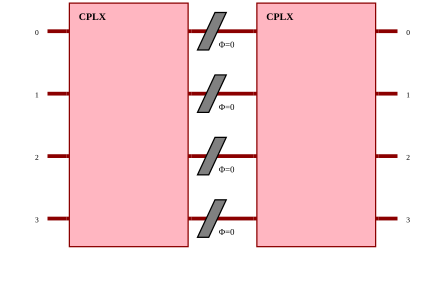

In [5]:
M = 4
phi = [pcvl.P(f"phi{i}") for i in range(M)]          # data-dependent phases

def mesh(prefix):
    return pcvl.GenericInterferometer(
        M, lambda i: pcvl.BS() // pcvl.PS(pcvl.P(f"{prefix}{i}")),
        shape=pcvl.InterferometerShape.RECTANGLE)

circuit = pcvl.Circuit(M)
circuit.add(0, mesh("a"))
for i in range(M):
    circuit.add(i, pcvl.PS(phi[i]))
circuit.add(0, mesh("b"))

# Freeze the random reservoir weights
for p in circuit.get_parameters():
    if not p.name.startswith("phi"):
        p.set_value(rng.uniform(0, 2 * np.pi))
for p in phi: p.set_value(0.0)

input_state = pcvl.BasicState([1, 1, 1, 1])
sim = Simulator(SLOSBackend())
pcvl.pdisplay(circuit)

In [6]:
def reservoir(P):
    """Map (n,4) phases -> (n,35) output-state probabilities."""
    feats = []
    for row in P:
        for p, v in zip(phi, row): p.set_value(float(v))
        sim.set_circuit(circuit)                       # recompute unitary for this input
        dist = sim.probs(input_state)
        feats.append(dist)
    keys = sorted({k for d in feats[:50] for k in d}, key=str)   # fixed output ordering
    return np.array([[d.get(k, 0.0) for k in keys] for d in feats]), keys

t0 = time.time()
R_tr, keys = reservoir(P_tr)
R_te, keys_te = reservoir(P_te)
print(f"reservoir states: train {R_tr.shape}, test {R_te.shape}  ({time.time()-t0:.1f}s)")
print("probability sum check:", R_tr.sum(1).min().round(6), R_tr.sum(1).max().round(6))

reservoir states: train (6500, 35), test (7047, 35)  (10.3s)
probability sum check: 1.0 1.0


## 3. Training process: learn attacks or learn normality?

We compare three ways to make a decision:

- **Logistic Regression on QORC features:** sees labeled normal and DoS examples. It learns to separate those known classes and uses a 0.5 probability cutoff. It has not been trained to recognize every kind of novelty.
- **Isolation Forest on QORC features:** sees only normal training examples. It scores how unusual a new record is in the 35-number optical feature space.
- **Isolation Forest on PCA features:** the classical comparison. It also sees only normal training examples, but works directly with the four PCA values rather than the optical output.

For each Isolation Forest, the cutoff is the 95th percentile of its training-normal anomaly scores. In plain language, the model marks the most unusual 5% of its normal training examples as the boundary for a warning. The test false-alarm rate may differ from 5%, because unseen test traffic can have a different distribution.

In [7]:
normal_train = train.family.eq('normal').to_numpy()
rs = StandardScaler().fit(R_tr)
readout = LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000)
readout.fit(rs.transform(R_tr), y_train)
score_q = readout.predict_proba(rs.transform(R_te))[:, 1]
pred_q = (score_q >= 0.5).astype(int)

# Each novelty detector sees only normal training examples; thresholds use their
# own training-normal anomaly-score distribution, never attack prevalence.
iso_reservoir = IsolationForest(n_estimators=300, random_state=SEED)
iso_reservoir.fit(R_tr[normal_train])
train_score_reservoir = -iso_reservoir.score_samples(R_tr[normal_train])
threshold_reservoir = np.quantile(train_score_reservoir, 0.95)
score_if_reservoir = -iso_reservoir.score_samples(R_te)
pred_if_reservoir = (score_if_reservoir > threshold_reservoir).astype(int)

iso_pca = IsolationForest(n_estimators=300, random_state=SEED)
iso_pca.fit(Z_tr[normal_train])
train_score_pca = -iso_pca.score_samples(Z_tr[normal_train])
threshold_pca = np.quantile(train_score_pca, 0.95)
score_if_pca = -iso_pca.score_samples(Z_te)
pred_if_pca = (score_if_pca > threshold_pca).astype(int)

print(f"Normal-only IF fit sizes: reservoir={normal_train.sum()}, PCA={normal_train.sum()}")
print(f"95th-percentile thresholds: reservoir={threshold_reservoir:.6f}, PCA-4={threshold_pca:.6f}")


Normal-only IF fit sizes: reservoir=4000, PCA=4000
95th-percentile thresholds: reservoir=0.570591, PCA-4=0.602973


## 4. Compare with classical detectors

The next cells print standard classification scores and then look at each attack family separately. In particular:

- **ROC-AUC** measures whether attacks tend to receive higher anomaly scores than normal records across many possible cutoffs. A score near 1 is strong ranking; 0.5 is roughly chance.
- **R2L recall** is the share of held-out R2L attacks that the model catches at the chosen cutoff. Higher means fewer zero-day examples are missed.
- **Normal false-positive rate (FPR)** is the share of normal test records incorrectly flagged as attacks. Lower means fewer unnecessary alerts.

No single number is enough: a model that flags every connection catches all attacks but also creates an unusable flood of false alarms. Consider recall together with FPR.

In [8]:
names = ['normal', 'anomaly']
models = [
    ("QORC + Logistic Regression", pred_q),
    ("QORC 35-D Isolation Forest", pred_if_reservoir),
    ("PCA-4 Isolation Forest", pred_if_pca),
]
for title, pred in models:
    print("=" * 70, f"\n{title}\n" + "=" * 70)
    print(classification_report(y_test, pred, target_names=names, digits=3, zero_division=0))


QORC + Logistic Regression
              precision    recall  f1-score   support

      normal      0.591     0.980     0.738      3000
     anomaly      0.971     0.498     0.658      4047

    accuracy                          0.703      7047
   macro avg      0.781     0.739     0.698      7047
weighted avg      0.809     0.703     0.692      7047

QORC 35-D Isolation Forest
              precision    recall  f1-score   support

      normal      0.519     0.950     0.672      3000
     anomaly      0.904     0.348     0.502      4047

    accuracy                          0.604      7047
   macro avg      0.712     0.649     0.587      7047
weighted avg      0.740     0.604     0.574      7047

PCA-4 Isolation Forest
              precision    recall  f1-score   support

      normal      0.502     0.947     0.656      3000
     anomaly      0.884     0.302     0.451      4047

    accuracy                          0.577      7047
   macro avg      0.693     0.625     0.553      70

,n,seen_in_train,QORC + Logistic recall,QORC 35-D IF recall,PCA-4 IF recall
family,,,,,
dos,1500,True,0.955,0.302,0.197
probe,1500,False,0.377,0.613,0.546
r2l,995,False,0.013,0.031,0.084
u2r,52,False,0.077,0.058,0.500
normal (specificity),3000,True,0.980,0.950,0.947


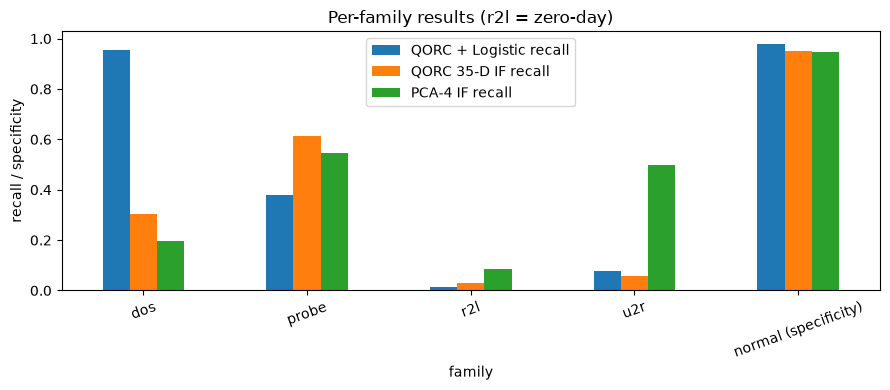

In [9]:
fam = test.family.values
models = {
    'QORC + Logistic': pred_q,
    'QORC 35-D IF': pred_if_reservoir,
    'PCA-4 IF': pred_if_pca,
}
rows = []
for f in ['dos', 'probe', 'r2l', 'u2r']:
    m = fam == f
    row = {'family': f, 'n': int(m.sum()), 'seen_in_train': f == 'dos'}
    row.update({f'{name} recall': pred[m].mean() for name, pred in models.items()})
    rows.append(row)
m = fam == 'normal'
row = {'family': 'normal (specificity)', 'n': int(m.sum()), 'seen_in_train': True}
row.update({f'{name} recall': 1 - pred[m].mean() for name, pred in models.items()})
rows.append(row)
res = pd.DataFrame(rows).set_index('family')
display(res.round(3))

ax = res[[f'{name} recall' for name in models]].plot.bar(figsize=(9, 4), rot=20)
ax.set_ylabel('recall / specificity'); ax.set_title('Per-family results (r2l = zero-day)')
plt.tight_layout(); plt.show()


In [10]:
normal_test = fam == 'normal'
r2l_test = fam == 'r2l'
metric_models = [
    ('QORC + Logistic', score_q, pred_q, '0.5 probability'),
    ('QORC 35-D IF', score_if_reservoir, pred_if_reservoir, f'train-normal p95 = {threshold_reservoir:.6f}'),
    ('PCA-4 IF', score_if_pca, pred_if_pca, f'train-normal p95 = {threshold_pca:.6f}'),
]
metrics = []
for name, score, pred, cutoff in metric_models:
    metrics.append({
        'model': name,
        'ROC-AUC': roc_auc_score(y_test, score),
        'r2l zero-day recall': pred[r2l_test].mean(),
        'normal FPR': pred[normal_test].mean(),
        'decision threshold': cutoff,
    })
display(pd.DataFrame(metrics).set_index('model').round(3))
print("Confusion matrices (true rows, predicted columns; normal, anomaly):")
for name, _, pred, _ in metric_models:
    print(f"{name}:\n{confusion_matrix(y_test, pred)}")


,ROC-AUC,r2l zero-day recall,normal FPR,decision threshold
model,,,,
QORC + Logistic,0.629,0.013,0.020,0.5 probability
QORC 35-D IF,0.904,0.031,0.050,train-normal p95 = 0.570591
PCA-4 IF,0.902,0.084,0.053,train-normal p95 = 0.602973


Confusion matrices (true rows, predicted columns; normal, anomaly):
QORC + Logistic:
[[2940   60]
 [2032 2015]]
QORC 35-D IF:
[[2851  149]
 [2640 1407]]
PCA-4 IF:
[[2840  160]
 [2823 1224]]


### What should we learn from the result?

A supervised classifier learns the difference between **normal and the known DoS examples**. It is not asked to learn what normal traffic looks like in general, so a new attack that does not resemble DoS may be mistaken for normal. A normal-only Isolation Forest has a more suitable goal for novelty detection: identify records that differ from the examples of normal traffic. That makes its learning objective a better fit for zero-day detection, but it still cannot guarantee that every new attack will look unusual.

In the saved run, the normal-only detectors have ROC-AUC around 0.90, while the supervised QORC readout is lower. At the selected threshold, however, R2L recall is modest; the PCA Isolation Forest catches more R2L examples than the reservoir Isolation Forest in this run. Thus the better anomaly-detection objective improves ranking overall, but it does **not** mean the QORC catches more of this particular zero-day family at the chosen alert rate.

The comparison also does not prove a quantum advantage: the photonic circuit is simulated, its settings are random and fixed, and it only transforms the four PCA values. Here, reservoir and PCA Isolation Forest ROC-AUC are very close. To support a stronger claim, repeat with multiple random seeds and compare against classical nonlinear feature maps of the same size.